# Background

- **Author**: 待學生確認（尚未確認本次對話者與實際分工）
- **Created At**: 2026-11-09
- **Research Motivation and Context (why are we interested in the findings?)：** 比較白人比例高（VT、ME、WV）與低（HI、DC、CA）兩個州群，在收入四分位組內白人、亞洲人與黑人的房貸核准率。兩群各合併全部申請紀錄計算，非州核准率的簡單平均。指定資料：[高白人比例組](../data/processed/state_VT-ME-WV_white_high_15_columns.csv)、[低白人比例組](../data/processed/state_HI-DC-CA_white_low_15_columns.csv)、[2024 ACS 州群家戶收入門檻](../data/processed/income_quartiles_by_race_2024.csv)。本 notebook 的讀取驗證與樣本說明同時記錄這三個既有輸入的核對結果；房貸資料上游產生程式與年份未確認，未據檔名推定其年份。
- **Main Findings and Takeaways：** 來源共 606,291 筆，排除收入缺失 24,729 筆，納入 581,562 筆。兩州群三種族的核准率均隨收入組別由 Q1 至 Q4 上升。Q1 低白人比例組的三種族核准率均較高；Q2–Q4 高白人比例組的三種族核准率均較高（Q3 白人僅相差約 0.09 個百分點）。高白人比例組 Q1 亞洲人僅 73 筆，區間較寬。已從乾淨 Jupyter kernel 完整執行，24 組結果表重新讀取驗證，四張圖與總覽圖已目視核對。兩群收入界線不同，屬描述性比較。
- **Future Direction：** 確認房貸資料年份；如需解釋種族差距，後續納入州別、貸款條件與機構差異。本次為描述性比較，不推論因果。


In [1]:
# Load packages
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib import font_manager
from IPython.display import Markdown
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams['font.family'] = next((f for f in ['Heiti TC', 'Arial Unicode MS', 'Noto Sans CJK TC'] if f in available_fonts), 'DejaVu Sans')
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.size'] = 11


Matplotlib is building the font cache; this may take a moment.


In [2]:
from pathlib import Path
import hashlib
import pandas as pd
from IPython.display import display

start = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (start, *start.parents) if (p/'AGENTS.md').is_file() and (p/'templates').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('請從 econ-5166-student-kit 或其子目錄執行。')
INPUTS = {
 'state_VT-ME-WV_white_high_15_columns.csv': 'eb1f7f550eb397ead2f900c142f1521cb4da04a892111b494b9a9d8f2eabbf51',
 'state_HI-DC-CA_white_low_15_columns.csv': '7bc8724fa2db17f65d8a77bb91929be14ae8f063ede116317d24598e49ca1554',
 'income_quartiles_by_race_2024.csv': '1f548f96289d381d9fd8434f5c6d385630998ad86b347c30f87986292ad624c9',
}
def read_verified(name):
    path=(PROJECT_ROOT/'data/processed'/name).resolve()
    assert path.is_relative_to((PROJECT_ROOT/'data/processed').resolve())
    if hashlib.sha256(path.read_bytes()).hexdigest()!=INPUTS[name]:
        raise ValueError(f'資料版本變更，請先核對：{name}')
    return pd.read_csv(path)
groups=['High White Population Share','Low White Population Share']
states=[{'VT','ME','WV'},{'HI','DC','CA'}]
races=['White','Asian','Black or African American']
parts=[]
for name,group,expected_states,expected_n in zip(list(INPUTS)[:2],groups,states,[81303,524988]):
    frame=read_verified(name)
    assert frame.shape==(expected_n,15)
    assert {'state_code','derived_race','income','action_taken'}<=set(frame)
    assert set(frame.state_code)==expected_states
    assert set(frame.derived_race)==set(races)
    assert set(frame.action_taken)=={1,2,3}
    frame['state_group']=group
    parts.append(frame)
df=pd.concat(parts,ignore_index=True)
display(df.head(10))
quartile_source=read_verified('income_quartiles_by_race_2024.csv')
assert len(quartile_source)==2 and quartile_source.race_group.is_unique
assert set(quartile_source.race_group)==set(groups)
assert quartile_source[['Q1','Median','Q3']].notna().all().all()
assert (quartile_source.Q1<quartile_source.Median).all() and (quartile_source.Median<quartile_source.Q3).all()
for group,expected in zip(groups,[{'Vermont','Maine','West Virginia'},{'Hawaii','District of Columbia','California'}]):
    actual=quartile_source.set_index('race_group').loc[group,'included_states']
    assert {s.strip() for s in actual.split(';')}==expected
display(quartile_source)
# race_group 在這份門檻檔代表州群，並不是申請人種族。
cutoffs=quartile_source.set_index('race_group')[['Q1','Median','Q3']].reindex(groups).rename(columns={'Q1':'P25','Median':'P50','Q3':'P75'})/1000
cutoffs.index.name='state_group'
income_numeric=pd.to_numeric(df.income,errors='coerce')
finite=income_numeric.notna() & np.isfinite(income_numeric)
analysis=df.loc[finite].copy()
analysis['income']=income_numeric.loc[analysis.index]
analysis['approved']=analysis.action_taken.isin([1,2]).astype(int)
analysis['income_quartile']=pd.Series(index=analysis.index,dtype='string')
for group in groups:
    mask=analysis.state_group.eq(group)
    analysis.loc[mask,'income_quartile']=pd.cut(analysis.loc[mask,'income'],[-np.inf,*cutoffs.loc[group],np.inf],labels=['Q1','Q2','Q3','Q4'],right=True).astype('string')
assert analysis.income_quartile.notna().all()


/var/folders/vv/vztwm8vd14nc5w3l5hb99_bm0000gn/T/ipykernel_22488/1060425136.py:20: DtypeWarning: Columns (9: loan_to_value_ratio, 10: property_value) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path)


,state_code,county_code,derived_ethnicity,derived_race,derived_sex,action_taken,loan_type,loan_purpose,loan_amount,loan_to_value_ratio,property_value,occupancy_type,income,debt_to_income_ratio,applicant_age,state_group
0,WV,54027.0,Not Hispanic or Latino,White,Joint,1,3,31,335000.0,NaN,NaN,1,NaN,NaN,55-64,High White Population Share
1,ME,23009.0,Not Hispanic or Latino,White,Male,1,1,32,135000.0,NaN,NaN,1,64.0,30%-<36%,55-64,High White Population Share
2,VT,50011.0,Not Hispanic or Latino,White,Male,1,3,32,325000.0,90.00000,365000,1,86.0,49,55-64,High White Population Share
3,VT,50017.0,Not Hispanic or Latino,White,Joint,1,2,32,285000.0,80.00000,345000,1,158.0,42,45-54,High White Population Share
4,WV,54003.0,Not Hispanic or Latino,White,Male,1,3,32,385000.0,90.00000,435000,1,283.0,30%-<36%,55-64,High White Population Share
5,WV,54003.0,Not Hispanic or Latino,White,Joint,1,2,31,365000.0,NaN,NaN,1,NaN,NaN,25-34,High White Population Share
6,ME,23019.0,Not Hispanic or Latino,White,Joint,1,2,31,325000.0,NaN,NaN,1,NaN,NaN,35-44,High White Population Share
7,VT,50015.0,Not Hispanic or Latino,White,Joint,3,2,32,325000.0,47.75000,665000,1,138.0,50%-60%,35-44,High White Population Share
8,WV,54037.0,Not Hispanic or Latino,White,Male,1,3,31,295000.0,NaN,NaN,1,NaN,NaN,25-34,High White Population Share
9,ME,23025.0,Not Hispanic or Latino,White,Female,1,3,31,195000.0,NaN,NaN,1,NaN,NaN,25-34,High White Population Share


,race_group,included_states,sample_size_before_cleaning,sample_size_after_cleaning,estimated_households,Q1,Median,Q3,IQR
0,High White Population Share,Vermont; Maine; West Virginia,22269,17090,1641630,35533.750,71067.50,121830.00,86296.250
1,Low White Population Share,California; District of Columbia; Hawaii,178545,149463,14620483,49239.625,100509.75,180105.35,130865.725


收入以千美元記錄，ACS 門檻以美元記錄；將門檻除以 1,000 後分組。每個州群的三種族共用該州群門檻。Q1：收入 ≤ P25；Q2：P25 < 收入 ≤ P50；Q3：P50 < 收入 ≤ P75；Q4：收入 > P75。保留有效負收入；只排除收入缺失或非有限值，不去除可能代表不同申請的相同列。

核准為 `action_taken` 1、2，拒絕為 3；核准率＝核准筆數／（核准＋拒絕筆數），不等同實際撥款率。輸入只有這三種結果及指定三種族。州群門檻來自一般家戶，不是房貸申請收入本身的分位數，因此各收入組的申請數不必各占 25%。


In [3]:
# Summary statistics for every variable used, before formal analysis
print(f'表 1：來源樣本 N={len(df):,}，有效收入 N={len(analysis):,}；收入單位：千美元')
display(income_numeric[finite].describe().to_frame('來源年收入'))
print('收入缺失或非有限值：',int((~finite).sum()))
display(pd.crosstab(df.state_group,finite).rename(columns={False:'收入無效／排除',True:'收入有效／納入'}))
for col in ['state_code','state_group','derived_race','action_taken']:
    counts=df[col].value_counts(dropna=True)
    print(f'表 2：來源 {col}，有效 N={counts.sum():,}，缺失 N={df[col].isna().sum():,}；比例分母為非缺失筆數')
    display(pd.DataFrame({'筆數':counts,'比例 (%)':counts/counts.sum()*100}))
print('表 3：兩州群 ACS 門檻摘要（美元），每群一列；Q1、Median、Q3 無缺失')
display(quartile_source[['Q1','Median','Q3']].describe().T)
print('included_states／race_group：兩群各一列、各占 50%；無缺失；僅作門檻對應，不代表申請人種族。')
print('表 4：分析樣本數值摘要（count 為有效 N；下列皆無缺失）')
display(analysis[['income','approved']].describe().T)
for col in ['state_code','state_group','derived_race','action_taken','income_quartile']:
    counts=analysis[col].value_counts(dropna=True)
    print(f'分析樣本 {col}：有效 N={counts.sum():,}；缺失 N={analysis[col].isna().sum():,}；比例分母為非缺失筆數')
    display(pd.DataFrame({'筆數':counts,'比例 (%)':counts/counts.sum()*100}))
print('圖表中的 n 是各州群／收入組／種族的有效申請數；沒有使用家戶權重或平均各州比率。')


表 1：來源樣本 N=606,291，有效收入 N=581,562；收入單位：千美元


,來源年收入
count,5.815620e+05
mean,2.517165e+02
std,1.714002e+04
min,-1.723100e+04
25%,8.900000e+01
50%,1.410000e+02
75%,2.270000e+02
max,1.080036e+07


收入缺失或非有限值： 24729


income,收入無效／排除,收入有效／納入
state_group,,
High White Population Share,2265,79038
Low White Population Share,22464,502524


表 2：來源 state_code，有效 N=606,291，缺失 N=0；比例分母為非缺失筆數


,筆數,比例 (%)
state_code,,
CA,502455,82.873571
ME,35186,5.803484
WV,33979,5.604404
HI,14146,2.333203
VT,12138,2.002009
DC,8387,1.383329


... (17 outputs left out)

,筆數,比例 (%)
action_taken,,
1,416814,71.671464
3,139436,23.976119
2,25312,4.352416


分析樣本 income_quartile：有效 N=581,562；缺失 N=0；比例分母為非缺失筆數


,筆數,比例 (%)
income_quartile,,
Q4,222511,38.260925
Q3,195865,33.679126
Q2,120934,20.794687
Q1,42252,7.265261


圖表中的 n 是各州群／收入組／種族的有效申請數；沒有使用家戶權重或平均各州比率。


### The actual analysis starts below

比較兩州群各收入組中的三種族核准率。使用 Wilson 95% 二項信賴區間；假定申請紀錄互相獨立，未調整同機構或重複申請相關性。


以下結果先合併同州群內的申請筆數，再按核准與拒絕計算；並非三州核准率的等權平均。兩群使用不同收入界線，Q1–Q4 表示相對於各州群家戶收入的位置，並非完全相同的美元收入。


In [4]:
# Wilson 95% intervals: descriptive binomial intervals, no lender clustering
idx = pd.MultiIndex.from_product([['Q1','Q2','Q3','Q4'],groups,races],names=['income_quartile','state_group','derived_race'])
summary = analysis.groupby(['income_quartile','state_group','derived_race']).agg(approved_n=('approved','sum'),n=('approved','size')).reindex(idx)
summary[['approved_n','n']] = summary[['approved_n','n']].fillna(0).astype(int)
summary['denied_n'] = summary.n-summary.approved_n
summary['approval_rate'] = summary.approved_n / summary.n.replace(0,np.nan)
z=1.959963984540054
n=summary.n.replace(0,np.nan)
p=summary.approval_rate
den=1+z*z/n
center=(p+z*z/(2*n))/den
half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
summary['ci95_low']=(center-half).clip(0,1)
summary['ci95_high']=(center+half).clip(0,1)
assert summary.n.sum()==len(analysis)
assert summary.approved_n.sum()==analysis.approved.sum()
valid = summary.n.gt(0)
assert summary.loc[valid,'approval_rate'].between(0,1).all()
assert (summary.loc[valid,'ci95_low'] <= summary.loc[valid,'approval_rate']+1e-12).all()
assert (summary.loc[valid,'ci95_high'] >= summary.loc[valid,'approval_rate']-1e-12).all()
print(f'表 6：各收入組、州群、種族的核准筆數、總筆數、核准率與 95% 信賴區間（總 N={len(analysis):,}）')
display(summary)
assets=PROJECT_ROOT/'finding/assets/white_groups_mortgage_approval'
assets.mkdir(parents=True,exist_ok=True)
summary.to_csv(assets/'approval_rates.csv')
cutoffs.to_csv(assets/'income_quartile_thresholds.csv')
# Reopen serialized result tables and verify their counts and values.
saved=pd.read_csv(assets/'approval_rates.csv')
assert len(saved)==24 and saved.n.sum()==len(analysis)
assert np.allclose(saved.approval_rate, summary.approval_rate, equal_nan=True)
assert np.allclose(pd.read_csv(assets/'income_quartile_thresholds.csv',index_col=0),cutoffs)


表 6：各收入組、州群、種族的核准筆數、總筆數、核准率與 95% 信賴區間（總 N=581,562）

approved_n  \
income_quartile state_group                 derived_race                            
Q1              High White Population Share White                            2518   
                                            Asian                              25   
                                            Black or African American          48   
                Low White Population Share  White                           13596   
                                            Asian                            3463   
                                            Black or African American        1121   
Q2              High White Population Share White                           14528   
                                            Asian                             177   
                                            Black or African American         358   
                Low White Population Share  White                           51971   
                                            Asian                            8748   
                                            Black or African American        4962   
Q3              High White Population Share White                           19726   
                                            Asian                             308   
                                            Black or African American         515   
                Low White Population Share  White                           97072   
                                            Asian                           27552   
                                            Black or African American        8643   
Q4              High White Population Share White                           21619   
                                            Asian                             570   
                                            Black or African American         318   
                Low White Population Share  White                          105240   
                                            Asian                           53360   
                                            Black or African American        5688   

                                                                            n  \
income_quartile state_group                 derived_race                        
Q1              High White Population Share White                        5449   
                                            Asian                          73   
                                            Black or African American     138   
                Low White Population Share  White                       27103   
                                            Asian                        6686   
                                            Black or African American    2803   
Q2              High White Population Share White                       20609   
                                            Asian                         259   
                                            Black or African American     547   
                Low White Population Share  White                       76221   
                                            Asian                       14755   
                                            Black or African American    8543   
Q3              High White Population Share White                       24696   
                                            Asian                         375   
                                            Black or African American     715   
                Low White Population Share  White                      121665   
                                            Asian                       36068   
                                            Black or African American   12346   
Q4              High White Population Share White                       25119   
                                            Asian                         647   
                                            Black or African American     411 

每張圖顯示一個收入組。長條為核准率；誤差線為 Wilson 95% 信賴區間；標籤 n 為有效收入的核准加拒絕申請數。空組標示無樣本，不填零。


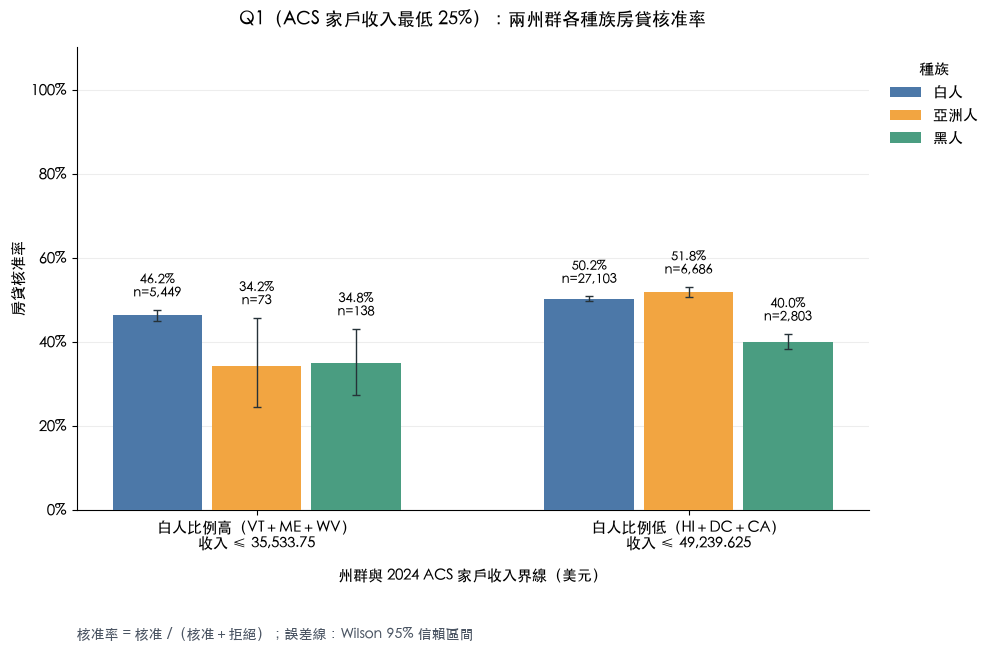

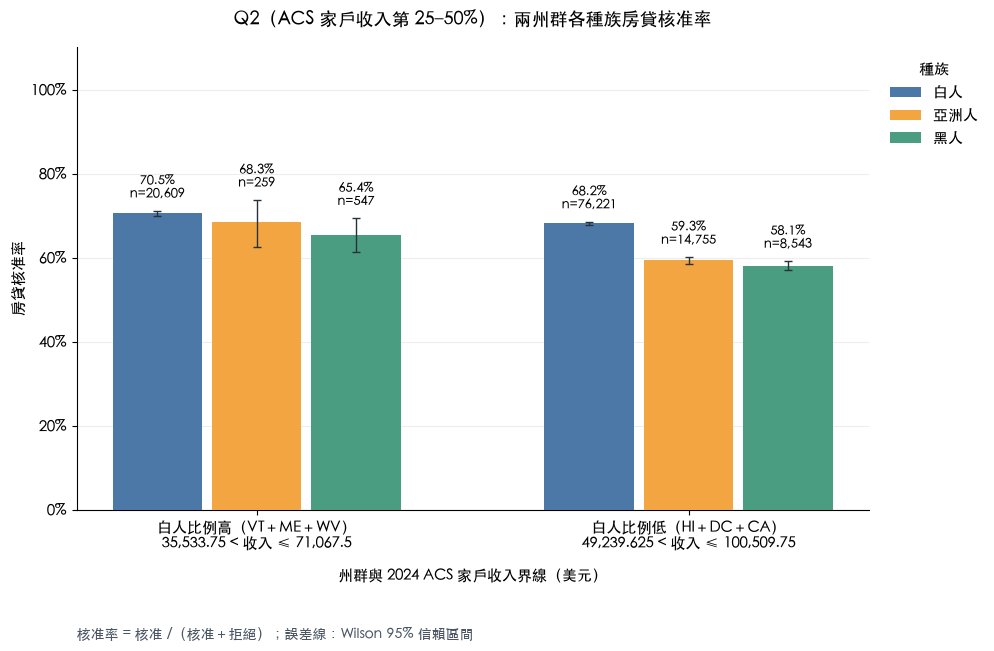

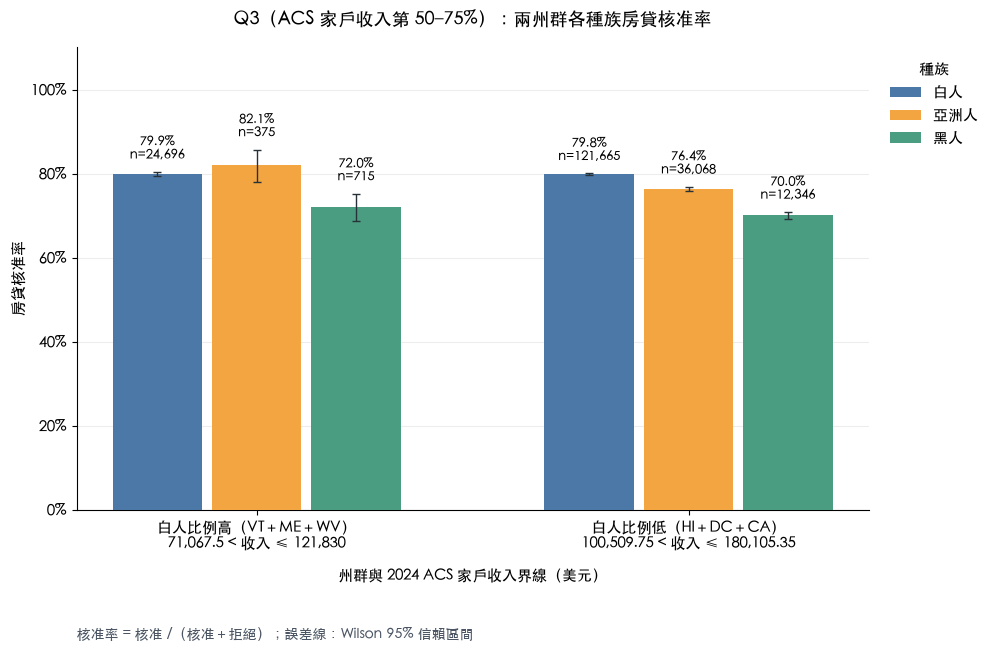

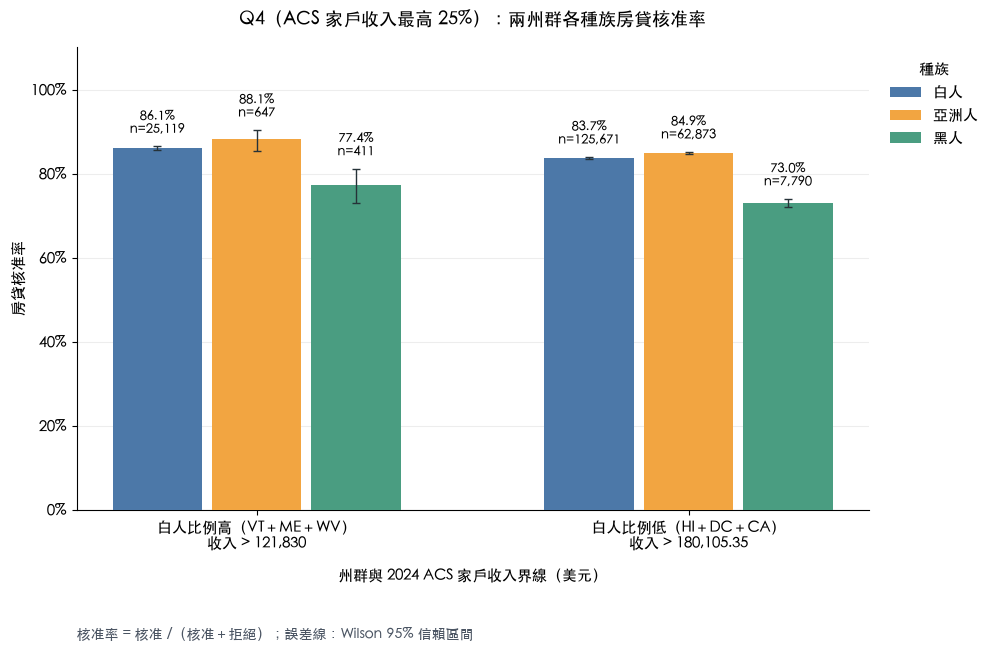

In [5]:
group_labels={groups[0]:'白人比例高（VT＋ME＋WV）',groups[1]:'白人比例低（HI＋DC＋CA）'}
colors=['#4C78A8','#F2A541','#4A9D81']
race_labels=['白人','亞洲人','黑人']
quartile_labels={'Q1':'ACS 家戶收入最低 25%','Q2':'ACS 家戶收入第 25–50%','Q3':'ACS 家戶收入第 50–75%','Q4':'ACS 家戶收入最高 25%'}
def income_range(state,q):
    a,b,c=[f'{v*1000:,.3f}'.rstrip('0').rstrip('.') for v in cutoffs.loc[state]]
    return {'Q1':f'收入 ≤ {a}', 'Q2':f'{a} < 收入 ≤ {b}', 'Q3':f'{b} < 收入 ≤ {c}', 'Q4':f'收入 > {c}'}[q]
def draw_chart(ax,q):
    width=.23
    for j,(race,label,color) in enumerate(zip(races,race_labels,colors)):
        group=summary.xs((q,race),level=('income_quartile','derived_race')).reindex(groups)
        x=np.arange(2)+(j-1)*width
        for k,row in enumerate(group.itertuples()):
            if row.n==0:
                ax.text(x[k],.025,'無樣本',ha='center',fontsize=9)
                continue
            ax.bar(x[k],row.approval_rate,width*.9,color=color,label=label if k==0 else None,zorder=3)
            ax.errorbar(x[k],row.approval_rate,yerr=[[max(0,row.approval_rate-row.ci95_low)],[max(0,row.ci95_high-row.approval_rate)]],fmt='none',ecolor='#263238',capsize=3,lw=1,zorder=4)
            ax.text(x[k],min(.99,row.ci95_high+.025),f'{row.approval_rate:.1%}\nn={row.n:,}',ha='center',va='bottom',fontsize=9)
    ax.set_title(f'{q}（{quartile_labels[q]}）：兩州群各種族房貸核准率',fontsize=13,pad=16)
    ax.set_xticks([0,1], [f'{group_labels[s]}\n{income_range(s,q)}' for s in groups])
    ax.set_xlabel('州群與 2024 ACS 家戶收入界線（美元）',labelpad=12)
    ax.set_ylabel('房貸核准率')
    ax.set_ylim(0,1.1)
    ax.set_yticks(np.arange(0,1.01,.2))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis='y',alpha=.22,zorder=0)
    ax.set_axisbelow(True)
    ax.spines[['top','right']].set_visible(False)
    ax.legend(title='種族',loc='upper left',bbox_to_anchor=(1.01,1),frameon=False)
for q in ['Q1','Q2','Q3','Q4']:
    fig,ax=plt.subplots(figsize=(11,7))
    draw_chart(ax,q)
    fig.text(.1,.025,'核准率 = 核准 /（核准＋拒絕）；誤差線：Wilson 95% 信賴區間',fontsize=10,color='#4b5563')
    fig.subplots_adjust(left=.1,right=.82,bottom=.21,top=.87)
    fig.savefig(assets/f'{q}_approval_rate.png',dpi=180,facecolor='white')
    plt.show()
    plt.close(fig)
# A combined overview supports easy comparison; the four separate files are also saved.
fig,axes=plt.subplots(2,2,figsize=(19,13))
for ax,q in zip(axes.flat,['Q1','Q2','Q3','Q4']):
    draw_chart(ax,q)
fig.subplots_adjust(left=.06,right=.92,bottom=.13,top=.93,wspace=.44,hspace=.58)
fig.text(.06,.025,'門檻：income_quartiles_by_race_2024.csv（2024 ACS 州群家戶收入）；核准 = action_taken 1、2；拒絕 = 3；誤差線：Wilson 95% 信賴區間',fontsize=12)
fig.savefig(assets/'all_quartiles.png',dpi=150,facecolor='white')
plt.close(fig)


本圖的州群構成不相同；低白人比例組的加州申請較多，因此合併比率主要反映該州的申請組成。兩群收入門檻不同，無法解讀為完全相同美元收入條件下的比較。房貸資料年份未確認，不能假定與 2024 ACS 同期。未控制信用、貸款條件、機構與州別差異；描述性差距不能解讀為歧視或因果效果。收入缺失排除亦可能影響組成。Wilson 區間未調整群聚相關性。作者待確認不影響數值計算，但交付前應補上實際作者。


In [6]:
for q in ['Q1','Q2','Q3','Q4']:
    lines=[]
    for race,label in zip(races,race_labels):
        high=summary.loc[(q,groups[0],race),'approval_rate']
        low=summary.loc[(q,groups[1],race),'approval_rate']
        lines.append(f'{label}：高白人比例組 {high:.1%}、低白人比例組 {low:.1%}（高−低 {(high-low)*100:+.1f} 個百分點）')
    display(Markdown(f'**{q}**：'+'；'.join(lines)+'。'))
print(f'執行完成：來源 {len(df):,} 筆；排除無效收入 {(~finite).sum():,} 筆；分析 {len(analysis):,} 筆。24 組結果已重新讀取核對；四張圖及總覽圖已儲存。')


**Q1**：白人：高白人比例組 46.2%、低白人比例組 50.2%（高−低 -4.0 個百分點）；亞洲人：高白人比例組 34.2%、低白人比例組 51.8%（高−低 -17.5 個百分點）；黑人：高白人比例組 34.8%、低白人比例組 40.0%（高−低 -5.2 個百分點）。

**Q2**：白人：高白人比例組 70.5%、低白人比例組 68.2%（高−低 +2.3 個百分點）；亞洲人：高白人比例組 68.3%、低白人比例組 59.3%（高−低 +9.1 個百分點）；黑人：高白人比例組 65.4%、低白人比例組 58.1%（高−低 +7.4 個百分點）。

**Q3**：白人：高白人比例組 79.9%、低白人比例組 79.8%（高−低 +0.1 個百分點）；亞洲人：高白人比例組 82.1%、低白人比例組 76.4%（高−低 +5.7 個百分點）；黑人：高白人比例組 72.0%、低白人比例組 70.0%（高−低 +2.0 個百分點）。

**Q4**：白人：高白人比例組 86.1%、低白人比例組 83.7%（高−低 +2.3 個百分點）；亞洲人：高白人比例組 88.1%、低白人比例組 84.9%（高−低 +3.2 個百分點）；黑人：高白人比例組 77.4%、低白人比例組 73.0%（高−低 +4.4 個百分點）。

執行完成：來源 606,291 筆；排除無效收入 24,729 筆；分析 581,562 筆。24 組結果已重新讀取核對；四張圖及總覽圖已儲存。
